In [1]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid
from numba import njit, prange
from numba_progress import ProgressBar
from scipy.stats import binned_statistic

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 4.114
eps = 1e-14 # For numerical stability

In [130]:
data = np.genfromtxt("stiff20_2.csv", skip_header=1, delimiter=",")
forces = data[:,:-1]
forces = np.pad(forces, ((0,0),(1,0)), constant_values=np.nan)
t = data[:, -1]
dt = np.diff(t).mean()

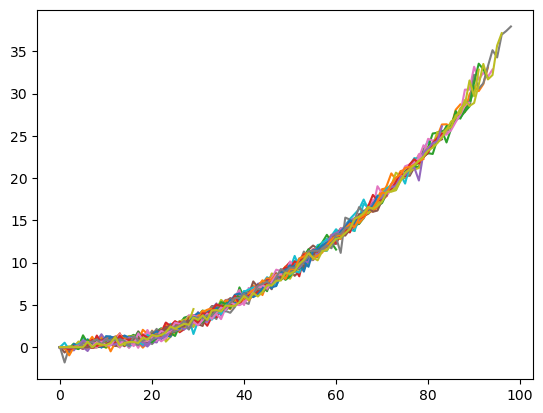

In [131]:
plt.plot(forces[:, :]);

In [132]:
event = np.argmin(~np.isnan(forces), axis=0)-1

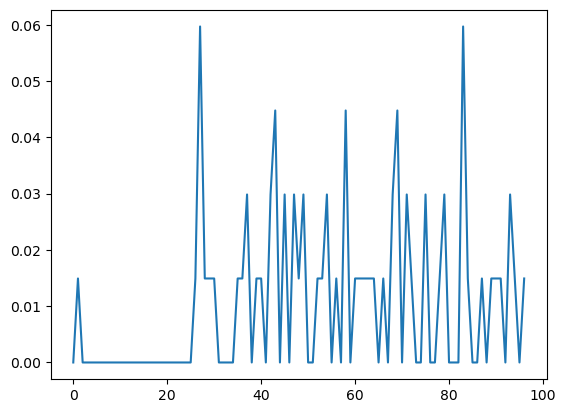

In [133]:
ru_GT = 0.15
xu_GT = 0.2
dropf_GT = 0

plen = np.histogram(event, bins=np.arange(0, event.max()))[0]
plen = plen / np.sum(plen)
plt.plot(plen)
logplen = np.log(plen + eps)

In [134]:
@njit(parallel=True)
def likelihood(logprior, ru, xu, forces_obs, event, dt, dropout_force):

    n_obs = forces_obs.shape[1]
    logpost = logprior

    for obs in prange(n_obs):

        len_f = int(event[obs]+1)
        f = forces_obs[:len_f, obs]
        for t in range(int(event[obs]+1)):
            F = forces_obs[t, obs]
            p = 1 - dt * ru * np.exp(F * xu / kbT)
            
            if p > 1:
                p = 1
            if p < 0:
                p = 0
            if t  == event[obs]:
                p = 1 - p

            logp = np.log(p+eps)
            logpost += logp
            
    return logpost

# Observations

In [135]:
likelihood(0, ru_GT, xu_GT, forces, event, dt, dropf_GT)

-323.5958205993798

# Inference

In [136]:
n_samples = 5000

ru = ru_GT
xu = xu_GT
dropf = 1*dropf_GT

RU = []
XU = []
DROPF = []

LOGL = -np.inf # Current chain likelihood

superstep = 5
attempts = 0
accepts = 0
pbar = tqdm(range(n_samples * superstep))
for s in pbar:

    # GIBBS RU
    ru_prop = ru + np.random.randn() * 8e-3
    
    LOGL_prop = likelihood(0, ru_prop, xu, forces, event, dt, dropf)
    attempts += 1
    thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
    a = np.random.rand()
    if a < thresh:
        accepts += 1
        LOGL = LOGL_prop
        ru = ru_prop

    # GIBBS XU
    xu_prop = xu + np.random.randn() * 8e-2
    
    LOGL_prop = likelihood(0, ru, xu_prop, forces, event, dt, dropf)
    attempts += 1
    thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
    a = np.random.rand()
    if a < thresh:
        accepts += 1
        LOGL = LOGL_prop
        xu = xu_prop


    # GIBBS CUTOFF FORCE
    if False:
        dropf_prop = np.abs(dropf + np.random.randn() * 1e-1)
        LOGL_prop = likelihood(0, ru, xu, forces, event, dt, dropf_prop)
        #LOGL_prop += -dropf_prop*100
        attempts += 1
        thresh = 1 if LOGL_prop > LOGL else np.exp(LOGL_prop - LOGL)
        a = np.random.rand()
        if a < thresh:
            accepts += 1
            LOGL = LOGL_prop
            dropf = dropf_prop

    if not s % superstep:
        RU.append(ru)
        XU.append(xu)
        DROPF.append(dropf)
        pbar.set_description(f"Acceptance: {int(100*accepts/attempts)}%. Progress")

  0%|          | 0/25000 [00:00<?, ?it/s]

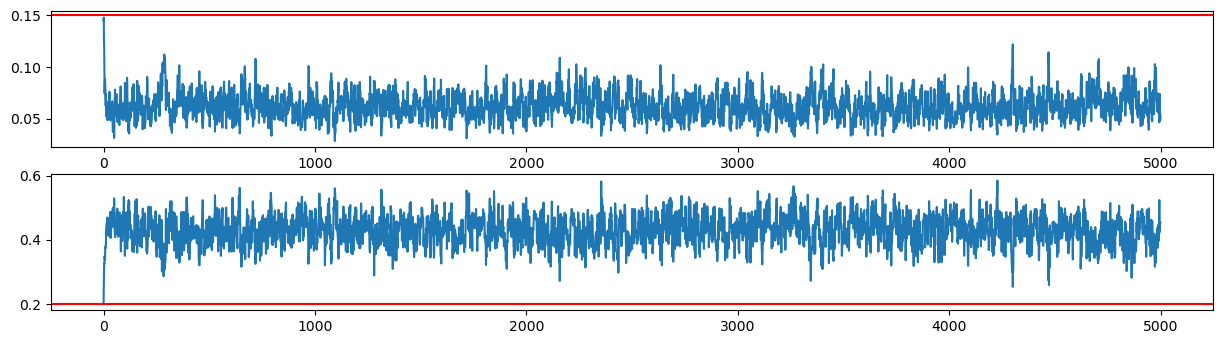

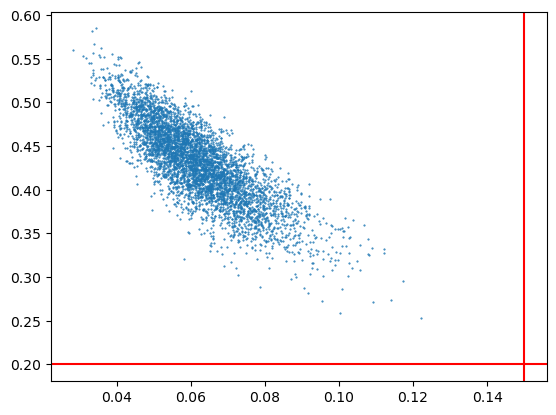

In [137]:
cut_warmup = 100
plt.figure(figsize=(15,6))
plt.subplot(3, 1, 1)
plt.plot(RU)
plt.axhline(ru_GT, c='r')
plt.subplot(3, 1, 2)
plt.plot(XU)
plt.axhline(xu_GT, c='r')
#plt.subplot(3, 1, 3)
#plt.plot(DROPF)
#plt.axhline(dropf_GT, c='r')
plt.show()
plt.plot(RU[cut_warmup:], XU[cut_warmup:], '.', ms=1)
#plt.xlim((0, 5*ru_GT))
plt.axvline(ru_GT, c='r')
plt.axhline(xu_GT, c='r')
#plt.ylim((0, 2*xu_GT))
plt.show()
#plt.hist(DROPF, bins=20, density=True);
#plt.axvline(dropf_GT, c='r')
#plt.xlabel("Rejection Threshold")